# Section 1 — Import Libraries & Configuration

In [1]:
# ============================================================
# Import Libraries
# ============================================================

import os
import json
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from sklearn.model_selection import train_test_split

print("Libraries Imported Successfully")

Libraries Imported Successfully


In [2]:
# ============================================================
# Project Directory
# ============================================================
  
PROJECT_DIR = "D:/Brac_thesis"

DATASET_DIR = os.path.join(
    PROJECT_DIR,
    "dataset"
)

PROCESSED_DATASET_DIR = os.path.join(
    DATASET_DIR,
    "processed"
)

METADATA_DIR = os.path.join(
    DATASET_DIR,
    "metadata"
)

In [3]:
# ============================================================
# Dataset Files
# ============================================================

TRAIN_CSV = os.path.join(
    PROCESSED_DATASET_DIR,
    "train.csv"
)

VALIDATION_CSV = os.path.join(
    PROCESSED_DATASET_DIR,
    "validation.csv"
)

TEST_CSV = os.path.join(
    PROCESSED_DATASET_DIR,
    "test.csv"
)

METADATA_PATH = os.path.join(
    METADATA_DIR,
    "metadata.json"
)

print("Dataset Paths Ready")

Dataset Paths Ready


In [4]:
# ============================================================
# Configuration
# ============================================================

SEED = 42

IMAGE_HEIGHT = 224
IMAGE_WIDTH = 224
CHANNELS = 3

IMAGE_EXTENSIONS = (".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff", ".webp")

random.seed(SEED)
np.random.seed(SEED)

print("Configuration Loaded Successfully")

Configuration Loaded Successfully


In [5]:
TRAIN_SIZE = 0.60

In [6]:
REMAINDER = 1.0 - TRAIN_SIZE
VALIDATION_SIZE = REMAINDER / 2
TEST_SIZE = REMAINDER / 2

In [7]:
# ============================================================
# Dataset Paths
# ============================================================

DATASET_DIR = os.path.join(PROJECT_DIR, "dataset")

RAW_DATASET_DIR = os.path.join(DATASET_DIR, "raw")

PROCESSED_DATASET_DIR = os.path.join(DATASET_DIR, "processed")

PROCESSED_IMAGES_DIR = os.path.join(PROCESSED_DATASET_DIR, "Images")

METADATA_DIR = os.path.join(DATASET_DIR, "metadata")

os.makedirs(PROCESSED_IMAGES_DIR, exist_ok=True)

os.makedirs(METADATA_DIR, exist_ok=True)

print("Dataset Paths Ready")

Dataset Paths Ready


In [8]:
# ============================================================
# Output Files
# ============================================================

# Processed dataset CSV files
DATASET_CSV = os.path.join(PROCESSED_DATASET_DIR, "dataset.csv")

TRAIN_CSV = os.path.join(PROCESSED_DATASET_DIR, "train.csv")

VALIDATION_CSV = os.path.join(PROCESSED_DATASET_DIR, "validation.csv")

TEST_CSV = os.path.join(PROCESSED_DATASET_DIR, "test.csv")

# Metadata files
METADATA_JSON = os.path.join(
    METADATA_DIR,
    "metadata.json"
)

CLASS_MAPPING_CSV = os.path.join(
    METADATA_DIR,
    "class_mapping.csv"
)

DATASET_STATISTICS_CSV = os.path.join(
    METADATA_DIR,
    "dataset_statistics.csv"
)

print("Output Files Ready")

Output Files Ready


In [9]:
# ============================================================
# Verify Dataset
# ============================================================

if not os.path.exists(RAW_DATASET_DIR):

    raise FileNotFoundError(

        f"Dataset folder '{RAW_DATASET_DIR}' was not found."

    )

print(f"Dataset Found : {RAW_DATASET_DIR}")

Dataset Found : D:/Brac_thesis\dataset\raw


In [10]:
# ============================================================
# Configuration Summary
# ============================================================

print("=" * 70)

print("CONFIGURATION SUMMARY")

print("=" * 70)

print(f"Random Seed        : {SEED}")

print(f"Image Size         : {IMAGE_WIDTH} x {IMAGE_HEIGHT}")

print(f"Channels           : {CHANNELS}")

print(f"Training Split     : {TRAIN_SIZE * 100:.0f}%")

print(f"Validation Split   : {VALIDATION_SIZE * 100:.0f}%")

print(f"Testing Split      : {TEST_SIZE * 100:.0f}%")

print("=" * 70)

CONFIGURATION SUMMARY
Random Seed        : 42
Image Size         : 224 x 224
Channels           : 3
Training Split     : 60%
Validation Split   : 20%
Testing Split      : 20%


In [11]:
# ============================================================
# Dataset Structure
# ============================================================

print("=" * 70)

print("RAW DATASET STRUCTURE")

print("=" * 70)

for disease in sorted(os.listdir(RAW_DATASET_DIR)):

    disease_path = os.path.join(
        RAW_DATASET_DIR,
        disease
    )

    if not os.path.isdir(disease_path):
        continue

    print(f"\n{disease}")

    for severity in sorted(os.listdir(disease_path)):

        severity_path = os.path.join(
            disease_path,
            severity
        )

        if not os.path.isdir(severity_path):
            continue

        image_count = len(

            [

                file

                for file in os.listdir(severity_path)

                if file.lower().endswith(IMAGE_EXTENSIONS)

            ]

        )

        print(f"   ├── {severity:<15} : {image_count}")

RAW DATASET STRUCTURE

Acne
   ├── Mild            : 650
   ├── Moderate        : 650
   ├── Severe          : 650

Eczema
   ├── Mild            : 650
   ├── Moderate        : 650
   ├── Severe          : 650

Normal
   ├── dry             : 758
   ├── normal          : 1274
   ├── oily            : 1120

burn
   ├── Mild            : 532
   ├── Moderate        : 490
   ├── Severe          : 201


In [12]:
# ============================================================
# Dataset Statistics
# ============================================================

total_diseases = 0
total_labels = 0
total_images = 0

for disease in sorted(os.listdir(RAW_DATASET_DIR)):

    disease_path = os.path.join(
        RAW_DATASET_DIR,
        disease
    )

    if not os.path.isdir(disease_path):
        continue

    total_diseases += 1

    for severity in sorted(os.listdir(disease_path)):

        severity_path = os.path.join(
            disease_path,
            severity
        )

        if not os.path.isdir(severity_path):
            continue

        total_labels += 1

        total_images += len(

            [

                file

                for file in os.listdir(severity_path)

                if file.lower().endswith(IMAGE_EXTENSIONS)

            ]

        )

print("=" * 70)

print("DATASET STATISTICS")

print("=" * 70)

print(f"Diseases : {total_diseases}")

print(f"Labels   : {total_labels}")

print(f"Images   : {total_images}")

DATASET STATISTICS
Diseases : 4
Labels   : 12
Images   : 8275


In [13]:
# ============================================================
# Verify Dataset Split
# ============================================================

assert abs(

    TRAIN_SIZE +

    VALIDATION_SIZE +

    TEST_SIZE - 1.0

) < 1e-8

print("Dataset Split Verified")

Dataset Split Verified


# Section 2 — Scan Dataset

In [14]:
# ============================================================
# Section 2 : Scan Dataset
# ============================================================

dataset_records = []

print("Scanning Dataset...")

Scanning Dataset...


In [15]:
# ============================================================
# Scan Dataset
# ============================================================

for disease in sorted(os.listdir(RAW_DATASET_DIR)):

    disease_path = os.path.join(
        RAW_DATASET_DIR,
        disease
    )

    if not os.path.isdir(disease_path):
        continue

    for severity in sorted(os.listdir(disease_path)):

        severity_path = os.path.join(
            disease_path,
            severity
        )

        if not os.path.isdir(severity_path):
            continue

        label = f"{disease}_{severity}"

        for image_name in sorted(os.listdir(severity_path)):

            if not image_name.lower().endswith(
                IMAGE_EXTENSIONS
            ):
                continue

            image_path = os.path.join(
                severity_path,
                image_name
            )

            dataset_records.append(

                {

                    "filepath": image_path,

                    "filename": image_name,

                    "disease": disease,

                    "severity": severity,

                    "label": label

                }

            )

print("Dataset Scanned Successfully")

Dataset Scanned Successfully


In [16]:
# ============================================================
# Create DataFrame
# ============================================================

dataset_df = pd.DataFrame(
    dataset_records
)

print(f"Total Images : {len(dataset_df)}")

Total Images : 8275


In [17]:
# ============================================================
# Sample Records
# ============================================================

dataset_df.head()

,filepath,filename,disease,severity,label
0,D:/Brac_thesis\dataset\raw\Acne\Mild\acne_mild...,acne_mild_001.jpg,Acne,Mild,Acne_Mild
1,D:/Brac_thesis\dataset\raw\Acne\Mild\acne_mild...,acne_mild_002.jpg,Acne,Mild,Acne_Mild
2,D:/Brac_thesis\dataset\raw\Acne\Mild\acne_mild...,acne_mild_003.jpg,Acne,Mild,Acne_Mild
3,D:/Brac_thesis\dataset\raw\Acne\Mild\acne_mild...,acne_mild_004.png,Acne,Mild,Acne_Mild
4,D:/Brac_thesis\dataset\raw\Acne\Mild\acne_mild...,acne_mild_005.jpg,Acne,Mild,Acne_Mild


In [18]:
# ============================================================
# Dataset Information
# ============================================================

print("=" * 70)

print("DATASET INFORMATION")

print("=" * 70)

dataset_df.info()

DATASET INFORMATION
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8275 entries, 0 to 8274
Data columns (total 5 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   filepath  8275 non-null   object
 1   filename  8275 non-null   object
 2   disease   8275 non-null   object
 3   severity  8275 non-null   object
 4   label     8275 non-null   object
dtypes: object(5)
memory usage: 323.4+ KB


In [19]:
# ============================================================
# Missing Values
# ============================================================

print("=" * 70)

print("MISSING VALUES")

print("=" * 70)

print(dataset_df.isnull().sum())

MISSING VALUES
filepath    0
filename    0
disease     0
severity    0
label       0
dtype: int64


In [20]:
# ============================================================
# Label Distribution
# ============================================================

label_counts = (

    dataset_df["label"]

    .value_counts()

    .sort_index()

)

print("=" * 70)

print("LABEL DISTRIBUTION")

print("=" * 70)

print(label_counts)

LABEL DISTRIBUTION
label
Acne_Mild           650
Acne_Moderate       650
Acne_Severe         650
Eczema_Mild         650
Eczema_Moderate     650
Eczema_Severe       650
Normal_dry          758
Normal_normal      1274
Normal_oily        1120
burn_Mild           532
burn_Moderate       490
burn_Severe         201
Name: count, dtype: int64


In [21]:
# ============================================================
# Disease Distribution
# ============================================================

disease_counts = (

    dataset_df["disease"]

    .value_counts()

    .sort_index()

)

print("=" * 70)

print("DISEASE DISTRIBUTION")

print("=" * 70)

print(disease_counts)

DISEASE DISTRIBUTION
disease
Acne      1950
Eczema    1950
Normal    3152
burn      1223
Name: count, dtype: int64


In [22]:
# ============================================================
# Severity Distribution
# ============================================================

severity_counts = (

    dataset_df["severity"]

    .value_counts()

    .sort_index()

)

print("=" * 70)

print("SEVERITY DISTRIBUTION")

print("=" * 70)

print(severity_counts)

SEVERITY DISTRIBUTION
severity
Mild        1832
Moderate    1790
Severe      1501
dry          758
normal      1274
oily        1120
Name: count, dtype: int64


# Section 3 — Validate Images

In [23]:
# ============================================================
# Section 3 : Validate Images
# ============================================================

valid_records = []

invalid_records = []

print("Validating Images...")

Validating Images...


In [24]:
# ============================================================
# Validate Images
# ============================================================

for _, row in dataset_df.iterrows():

    image_path = row["filepath"]

    try:

        with Image.open(image_path) as image:

            image.verify()

        with Image.open(image_path) as image:

            width, height = image.size

            mode = image.mode

        valid_records.append(

            {

                **row.to_dict(),

                "width": width,

                "height": height,

                "mode": mode

            }

        )

    except Exception as error:

        invalid_records.append(

            {

                "filepath": image_path,

                "error": str(error)

            }

        )

print("Validation Completed")

Validation Completed


In [25]:
# ============================================================
# Create Validation DataFrames
# ============================================================

valid_df = pd.DataFrame(valid_records)

invalid_df = pd.DataFrame(invalid_records)

print(f"Valid Images   : {len(valid_df)}")

print(f"Invalid Images : {len(invalid_df)}")

Valid Images   : 8275
Invalid Images : 0


In [26]:
# ============================================================
# Resolution Summary
# ============================================================

resolution_summary = (

    valid_df

    .groupby(

        ["width", "height"]

    )

    .size()

    .reset_index(name="count")

    .sort_values(

        "count",

        ascending=False

    )

)

resolution_summary

,width,height,count
767,640,640,3152
930,720,472,713
593,477,720,350
348,294,222,334
938,720,480,331
...,...,...,...
40,172,289,1
41,172,294,1
42,172,295,1
43,174,215,1


In [27]:
# ============================================================
# Image Mode Summary
# ============================================================

mode_summary = (

    valid_df["mode"]

    .value_counts()

)

mode_summary

mode
RGB     8075
RGBA     198
P          2
Name: count, dtype: int64

In [28]:
# ============================================================
# Invalid Images
# ============================================================

if invalid_df.empty:

    print("No Invalid Images Found")

else:

    display(invalid_df)

No Invalid Images Found


In [29]:
# ============================================================
# Keep Only Valid Images
# ============================================================

dataset_df = valid_df.copy()

dataset_df.reset_index(

    drop=True,

    inplace=True

)

print("Only Valid Images Retained")

Only Valid Images Retained


In [30]:
# ============================================================
# Validation Summary
# ============================================================

print("=" * 70)

print("VALIDATION SUMMARY")

print("=" * 70)

print(f"Valid Images     : {len(dataset_df)}")

print(f"Invalid Images   : {len(invalid_df)}")

print(f"Unique Resolutions : {resolution_summary.shape[0]}")

print(f"Image Modes        : {dataset_df['mode'].nunique()}")

print("=" * 70)

VALIDATION SUMMARY
Valid Images     : 8275
Invalid Images   : 0
Unique Resolutions : 1303
Image Modes        : 3


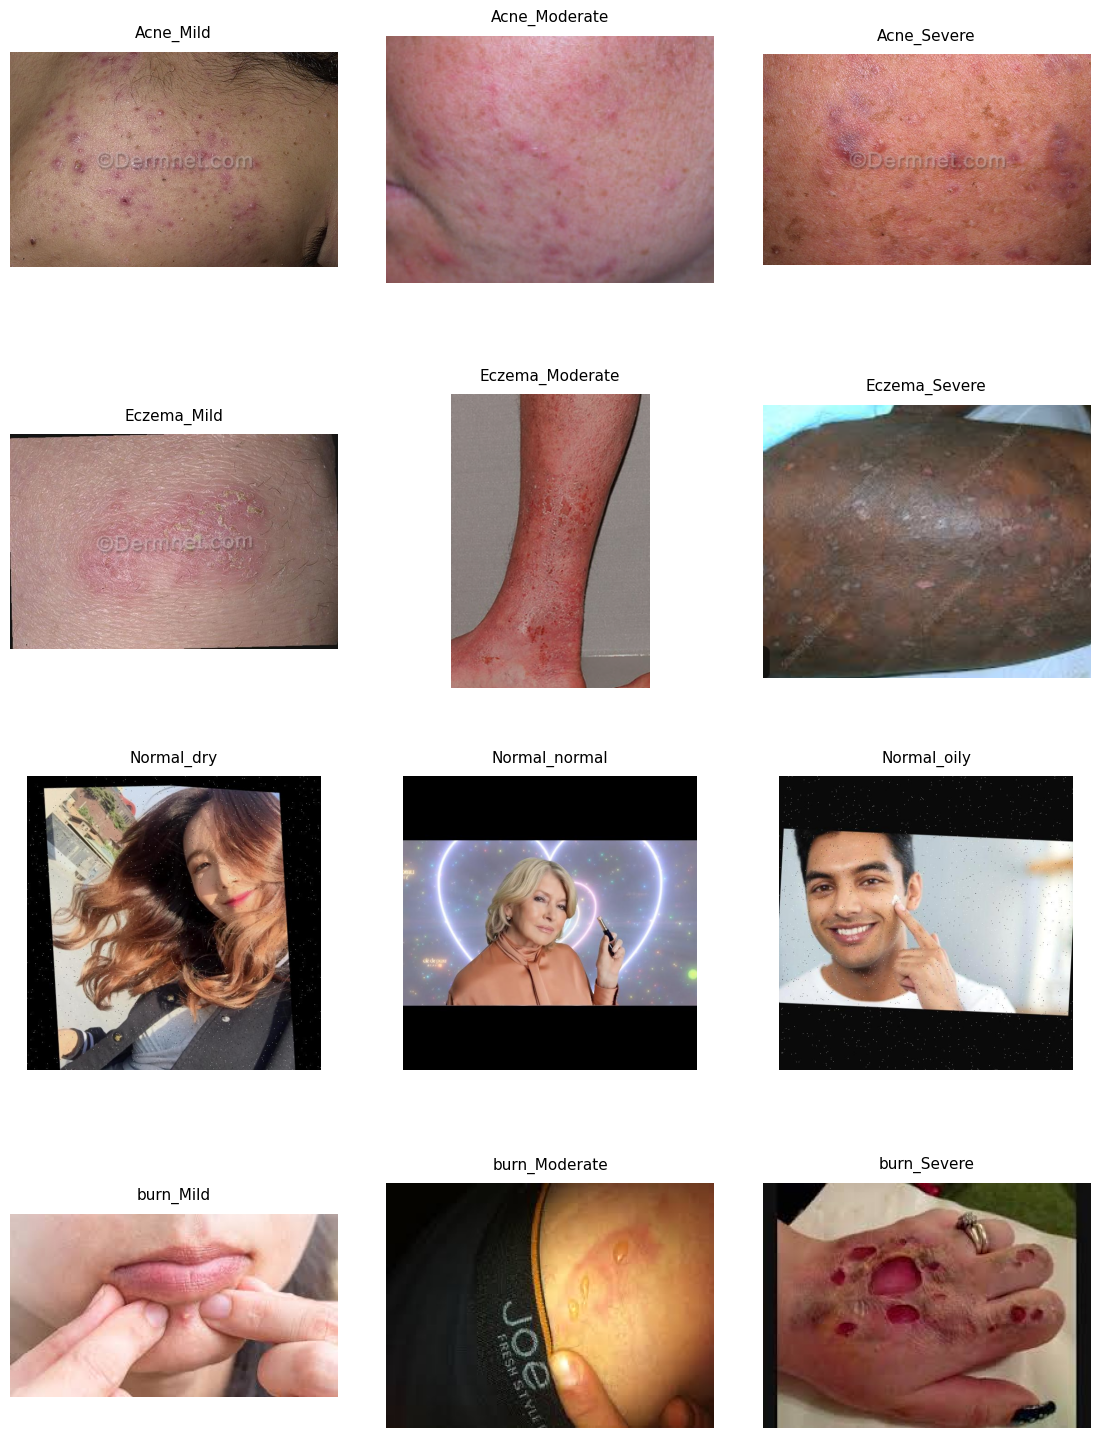

In [38]:
# ============================================================
# Preview One Random Image From Each Label
# ============================================================

label_samples = (
    dataset_df
    .groupby("label", sort=True, group_keys=False)
    .sample(n=1)
    .reset_index(drop=True)
)

num_labels = len(label_samples)

columns = 3
rows = (num_labels + columns - 1) // columns

fig, axes = plt.subplots(
    rows,
    columns,
    figsize=(12, 4 * rows)
)

# Handle cases with one row or one image
axes = np.array(axes).reshape(-1)

for index, (_, row) in enumerate(label_samples.iterrows()):
    image = Image.open(row["filepath"]).convert("RGB")

    axes[index].imshow(image)
    axes[index].set_title(
        row["label"],
        fontsize=11,
        pad=10
    )
    axes[index].axis("off")

# Hide unused subplot positions
for index in range(num_labels, len(axes)):
    axes[index].axis("off")

# Consistent spacing and margins
plt.subplots_adjust(
    left=0.05,
    right=0.95,
    top=0.95,
    bottom=0.05,
    wspace=0.15,
    hspace=0.30
)

plt.show()

# Section 4 — Resize & Save Images

In [32]:
# ============================================================
# Section 4 : Resize & Save Images
# ============================================================

processed_records = []

print("Processing Images...")

Processing Images...


In [33]:
# ============================================================
# Resize & Save Images
# ============================================================

for _, row in dataset_df.iterrows():

    source_path = row["filepath"]

    disease = row["disease"]

    severity = row["severity"]

    filename = row["filename"]

    output_filename = f"{disease}_{severity}_{filename}"

    output_path = os.path.join(

        PROCESSED_IMAGES_DIR,

        output_filename

    )

    with Image.open(source_path) as image:

        if image.mode != "RGB":

            image = image.convert("RGB")

        if image.size != (

            IMAGE_WIDTH,

            IMAGE_HEIGHT

        ):

            image = image.resize(

                (

                    IMAGE_WIDTH,

                    IMAGE_HEIGHT

                ),

                Image.Resampling.LANCZOS

            )

        image.save(

            output_path,

            quality=100

        )

    processed_records.append(

        {

            **row.to_dict(),

            "filepath": output_path

        }

    )

print("Image Processing Completed")

Image Processing Completed


In [34]:
# ============================================================
# Create Processed Dataset
# ============================================================

processed_df = pd.DataFrame(

    processed_records

)

print(

    f"Processed Images : {len(processed_df)}"

)

Processed Images : 8275


In [ ]:
# ============================================================
# Verify Image Size
# ============================================================

image_sizes = []

for image_path in processed_df["filepath"]:

    with Image.open(image_path) as image:

        image_sizes.append(

            image.size

        )

print(

    pd.Series(

        image_sizes

    ).value_counts()

)

In [ ]:
# ============================================================
# Verify Image Mode
# ============================================================

image_modes = []

for image_path in processed_df["filepath"]:

    with Image.open(image_path) as image:

        image_modes.append(

            image.mode

        )

print(

    pd.Series(

        image_modes

    ).value_counts()

)

In [ ]:
# ============================================================
# Preview Images
# ============================================================

label_samples = (

    processed_df

    .groupby(

        "label",

        sort=True

    )

    .sample(

        n=1,

        random_state=SEED

    )

)

num_labels = len(label_samples)

columns = 3

rows = (

    num_labels + columns - 1

) // columns

plt.figure(

    figsize=(12, 4 * rows)

)

for index, (_, row) in enumerate(

    label_samples.iterrows()

):

    image = Image.open(

        row["filepath"]

    )

    plt.subplot(

        rows,

        columns,

        index + 1

    )

    plt.imshow(image)

    plt.title(

        row["label"],

        fontsize=10

    )

    plt.axis("off")

plt.tight_layout()

plt.show()

In [ ]:
# ============================================================
# Update Dataset
# ============================================================

dataset_df = processed_df.copy()

dataset_df.reset_index(

    drop=True,

    inplace=True

)

print("Dataset Updated")

In [ ]:
# ============================================================
# Verify Saved Images
# ============================================================

total_processed = len(

    [

        file

        for file in os.listdir(

            PROCESSED_IMAGES_DIR

        )

        if file.lower().endswith(

            IMAGE_EXTENSIONS

        )

    ]

)

print(

    f"Images Saved : {total_processed}"

)

In [ ]:
# ============================================================
# Processing Summary
# ============================================================

print("=" * 70)

print("PROCESSING SUMMARY")

print("=" * 70)

print(

    f"Total Images : {len(dataset_df)}"

)

print(

    f"Image Size   : {IMAGE_WIDTH} x {IMAGE_HEIGHT}"

)

print(

    "Color Mode   : RGB"

)

print("=" * 70)

# Section 5 — Create Dataset CSV

In [ ]:
# ============================================================
# Section 5 : Create Dataset CSV
# ============================================================

dataset_df = dataset_df[

    [

        "filepath",

        "filename",

        "disease",

        "severity",

        "label"

    ]

].copy()

print("Dataset Columns Selected")

In [ ]:
# ============================================================
# Sort Dataset
# ============================================================

dataset_df = dataset_df.sort_values(

    by=[

        "disease",

        "severity",

        "filename"

    ]

).reset_index(

    drop=True

)

print("Dataset Sorted Successfully")

In [ ]:
# ============================================================
# Duplicate Check
# ============================================================

duplicate_count = dataset_df.duplicated(

    subset=["filepath"]

).sum()

print("=" * 70)

print("DUPLICATE CHECK")

print("=" * 70)

print(f"Duplicate Images : {duplicate_count}")

In [ ]:
# ============================================================
# Label Distribution
# ============================================================

label_distribution = (

    dataset_df["label"]

    .value_counts()

    .sort_index()

)

print("=" * 70)

print("LABEL DISTRIBUTION")

print("=" * 70)

print(label_distribution)

In [ ]:
# ============================================================
# Save Dataset CSV
# ============================================================

dataset_df.to_csv(

    DATASET_CSV,

    index=False

)

print(

    f"Dataset Saved : {DATASET_CSV}"

)

In [ ]:
# ============================================================
# Verify Saved Dataset
# ============================================================

verify_df = pd.read_csv(

    DATASET_CSV

)

print(

    f"Rows Loaded : {len(verify_df)}"

)

In [ ]:
# ============================================================
# Dataset Preview
# ============================================================

verify_df.head(10)

In [ ]:
# ============================================================
# Dataset Information
# ============================================================

print("=" * 70)

print("DATASET INFORMATION")

print("=" * 70)

verify_df.info()

In [ ]:
# ============================================================
# Dataset Summary
# ============================================================

print("=" * 70)

print("DATASET SUMMARY")

print("=" * 70)

print(

    f"Total Images     : {len(verify_df)}"

)

print(

    f"Total Diseases   : {verify_df['disease'].nunique()}"

)

print(

    f"Total Severities : {verify_df['severity'].nunique()}"

)

print(

    f"Total Labels     : {verify_df['label'].nunique()}"

)

print("=" * 70)

# Section 6 — Train / Validation / Test Split

In [ ]:
# ============================================================
# Section 6 : Train / Validation / Test Split
# ============================================================

dataset_df = pd.read_csv(DATASET_CSV)

print(f"Dataset Loaded : {len(dataset_df)} Images")

In [ ]:
# ============================================================
# Train / Temporary Split
# ============================================================

train_df, temp_df = train_test_split(

    dataset_df,

    train_size=TRAIN_SIZE,

    stratify=dataset_df["label"],

    random_state=SEED,

    shuffle=True

)

print("Training Split Completed")

In [ ]:
# ============================================================
# Validation / Test Split
# ============================================================

validation_ratio = VALIDATION_SIZE / (

    VALIDATION_SIZE +

    TEST_SIZE

)

validation_df, test_df = train_test_split(

    temp_df,

    train_size=validation_ratio,

    stratify=temp_df["label"],

    random_state=SEED,

    shuffle=True

)

print("Validation/Test Split Completed")

In [ ]:
# ============================================================
# Reset Index
# ============================================================

train_df = train_df.reset_index(drop=True)

validation_df = validation_df.reset_index(drop=True)

test_df = test_df.reset_index(drop=True)

print("Index Reset Completed")

In [ ]:
# ============================================================
# Save Split CSV Files
# ============================================================

train_df.to_csv(

    TRAIN_CSV,

    index=False

)

validation_df.to_csv(

    VALIDATION_CSV,

    index=False

)

test_df.to_csv(

    TEST_CSV,

    index=False

)

print("CSV Files Saved Successfully")

In [ ]:
# ============================================================
# Split Statistics
# ============================================================

print("=" * 70)

print("DATASET SPLIT")

print("=" * 70)

print(f"Training Images   : {len(train_df)}")

print(f"Validation Images : {len(validation_df)}")

print(f"Testing Images    : {len(test_df)}")

print(f"Total Images      : {len(dataset_df)}")

print("=" * 70)

In [ ]:
# ============================================================
# Label Distribution
# ============================================================

summary_df = pd.DataFrame({

    "Train": train_df["label"].value_counts(),

    "Validation": validation_df["label"].value_counts(),

    "Test": test_df["label"].value_counts()

}).fillna(0).astype(int)

summary_df = summary_df.sort_index()

summary_df

In [ ]:
# ============================================================
# Split Ratio
# ============================================================

print("=" * 70)

print("SPLIT RATIO")

print("=" * 70)

print(f"Train      : {len(train_df)/len(dataset_df):.2%}")

print(f"Validation : {len(validation_df)/len(dataset_df):.2%}")

print(f"Test       : {len(test_df)/len(dataset_df):.2%}")

print("=" * 70)

In [ ]:
# ============================================================
# Verify CSV Files
# ============================================================

print("=" * 70)

print("CSV FILES")

print("=" * 70)

print(TRAIN_CSV)

print(VALIDATION_CSV)

print(TEST_CSV)

# Section 7 — Create Metadata

In [ ]:
# ============================================================
# Section 7 : Create Metadata
# ============================================================

dataset_df = pd.read_csv(DATASET_CSV)

print(f"Dataset Loaded : {len(dataset_df)} Images")

In [ ]:
# ============================================================
# Generate Labels
# ============================================================

labels = sorted(

    dataset_df["label"].unique()

)

print(f"Total Labels : {len(labels)}")

In [ ]:
# ============================================================
# Label Mapping
# ============================================================

label_to_index = {

    label: index

    for index, label in enumerate(labels)

}

index_to_label = {

    index: label

    for label, index in label_to_index.items()

}

print("Label Mapping Created")

In [ ]:
# ============================================================
# Metadata Dictionary
# ============================================================

metadata = {

    "image_height": IMAGE_HEIGHT,

    "image_width": IMAGE_WIDTH,

    "channels": CHANNELS,

    "train_size": TRAIN_SIZE,

    "validation_size": VALIDATION_SIZE,

    "test_size": TEST_SIZE,

    "total_images": len(dataset_df),

    "total_labels": len(labels),

    "labels": labels,

    "label_to_index": label_to_index,

    "index_to_label": index_to_label

}

print("Metadata Dictionary Created")

In [ ]:
# ============================================================
# Save Metadata
# ============================================================

with open(

    METADATA_JSON,

    "w"

) as file:

    json.dump(

        metadata,

        file,

        indent=4

    )

print(

    f"Metadata Saved : {METADATA_JSON}"

)

In [ ]:
# ============================================================
# Verify Metadata
# ============================================================

with open(

    METADATA_JSON,

    "r"

) as file:

    metadata = json.load(file)

print("Metadata Loaded Successfully")

In [ ]:
# ============================================================
# Labels
# ============================================================

print("=" * 70)

print("LABELS")

print("=" * 70)

for index, label in enumerate(

    metadata["labels"]

):

    print(f"{index:>2} : {label}")

In [ ]:
# ============================================================
# Metadata Summary
# ============================================================

print("=" * 70)

print("METADATA SUMMARY")

print("=" * 70)

print(f"Image Size     : {metadata['image_width']} x {metadata['image_height']}")

print(f"Channels       : {metadata['channels']}")

print(f"Total Images   : {metadata['total_images']}")

print(f"Total Labels   : {metadata['total_labels']}")

print("=" * 70)

In [ ]:
# ============================================================
# Label Mapping
# ============================================================

mapping_df = pd.DataFrame({

    "Index": list(metadata["label_to_index"].values()),

    "Label": list(metadata["label_to_index"].keys())

})

mapping_df.sort_values(

    "Index",

    inplace=True

)

mapping_df.reset_index(

    drop=True,

    inplace=True

)

mapping_df

# Section 8 — Final Verification

In [ ]:
# ============================================================
# Section 8 : Final Verification
# ============================================================

required_files = [

    DATASET_CSV,

    TRAIN_CSV,

    VALIDATION_CSV,

    TEST_CSV,

    METADATA_JSON

]

print("=" * 70)

print("OUTPUT FILES")

print("=" * 70)

for file in required_files:

    if os.path.exists(file):

        print(f"✓ {os.path.basename(file)}")

    else:

        print(f"✗ {os.path.basename(file)}")

In [ ]:
# ============================================================
# Load Generated Files
# ============================================================

dataset_df = pd.read_csv(DATASET_CSV)

train_df = pd.read_csv(TRAIN_CSV)

validation_df = pd.read_csv(VALIDATION_CSV)

test_df = pd.read_csv(TEST_CSV)

with open(

    METADATA_JSON,

    "r"

) as file:

    metadata = json.load(file)

print("All Files Loaded Successfully")

In [ ]:
# ============================================================
# Dataset Size Verification
# ============================================================

assert (

    len(train_df)

    + len(validation_df)

    + len(test_df)

) == len(dataset_df)

print("=" * 70)

print("DATASET SIZE")

print("=" * 70)

print(f"Total Images      : {len(dataset_df)}")

print(f"Training Images   : {len(train_df)}")

print(f"Validation Images : {len(validation_df)}")

print(f"Testing Images    : {len(test_df)}")

In [ ]:
# ============================================================
# Verify Labels
# ============================================================

dataset_labels = sorted(

    dataset_df["label"].unique()

)

metadata_labels = sorted(

    metadata["labels"]

)

assert dataset_labels == metadata_labels

print("Label Verification Passed")

In [ ]:
# ============================================================
# Missing Values
# ============================================================

print("=" * 70)

print("MISSING VALUES")

print("=" * 70)

print(dataset_df.isnull().sum())

In [ ]:
# ============================================================
# Image File Verification
# ============================================================

missing_images = []

for image_path in dataset_df["filepath"]:

    if not os.path.exists(image_path):

        missing_images.append(image_path)

print("=" * 70)

print("IMAGE FILES")

print("=" * 70)

print(f"Missing Images : {len(missing_images)}")

In [ ]:
# ============================================================
# Random Samples
# ============================================================

dataset_df.sample(

    10,

    random_state=SEED

)

In [ ]:
# ============================================================
# Metadata Summary
# ============================================================

print("=" * 70)

print("METADATA")

print("=" * 70)

for key, value in metadata.items():

    if isinstance(value, dict):

        print(f"{key} : {len(value)} Entries")

    elif isinstance(value, list):

        print(f"{key} : {len(value)} Items")

    else:

        print(f"{key} : {value}")

In [ ]:
# ============================================================
# Final Summary
# ============================================================

print("=" * 70)

print("DATA PREPROCESSING SUMMARY")

print("=" * 70)

print(f"Processed Images     : {len(dataset_df)}")

print(f"Training Images      : {len(train_df)}")

print(f"Validation Images    : {len(validation_df)}")

print(f"Testing Images       : {len(test_df)}")

print()

print(f"Total Labels         : {metadata['total_labels']}")

print(f"Image Size           : {metadata['image_width']} x {metadata['image_height']}")

print("=" * 70)